## 1. Библиотеки

In [194]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

* ID - Идентификатор настольной игры
* Name - Имя
* Year Published - Год публикации
* Min Players - Рекомендуемое минимальное количество игроков
* Max Players - Рекомендуемое максимальное количество игроков
* Play Time - Время игры
* Min Age - Рекомендуемый минимальный возраст игроков
* Users Rated - Количество пользователей, оценивших игру
* Rating Average - Средний рейтинг, полученный игрой (целевая переменная)
* BGG Rank - Рейтинг от BGG
* Complexity Average - Среднее значение сложности игры
* Owned Users - Количество зарегистрированных BGG владельцев игры
* Mechanics - Механика, используемая в игре
* Domains - Домены настольных игр, которым принадлежит игра

In [195]:
train = pd.read_csv("train_data.csv")
test = pd.read_csv("test_data.csv")

train["Rating Average"] = train["Rating Average"].str.replace(",", ".").astype(float)

for table in [train, test]:
    table["Complexity Average"] = table["Complexity Average"].str.replace(",", ".").astype(float)

print("Размер train:", train.shape)
print("Размер test:", test.shape)
print("Полностью повторяющихся строк в train:", train.duplicated().sum())

Размер train: (15257, 14)
Размер test: (5086, 13)
Полностью повторяющихся строк в train: 0


In [196]:
print(f'Пропуски train: {train.isna().sum()}')
print(f'Пропуски test": {test.isna().sum()}')

Пропуски train: ID                      10
Name                     0
Year Published           1
Min Players              0
Max Players              0
Play Time                0
Min Age                  0
Users Rated              0
Rating Average           0
BGG Rank                 0
Complexity Average       0
Owned Users             17
Mechanics             1200
Domains               7649
dtype: int64
Пропуски test": ID                       6
Name                     0
Year Published           0
Min Players              0
Max Players              0
Play Time                0
Min Age                  0
Users Rated              0
BGG Rank                 0
Complexity Average       0
Owned Users              6
Mechanics              398
Domains               2510
dtype: int64


### Что делаем с пропусками

* В Domains и Mechanics заменяем пропуски на Unknown.
* В числовых признаках используем медиану только обучающей части.
* ID исключаем из признаков.
* Name, Mechanics и Domains пока не включаем в модель. Это осознанное упрощение: используем девять числовых признаков, чтобы сравнить пройденные методы без дополнительного кодирования текста.

В Rating Average пропусков нет. Строки из-за пропусков не удаляем.

In [197]:
for table in [train, test]:
    table["Domains"] = table["Domains"].fillna("Unknown Domains")
    table["Mechanics"] = table["Mechanics"].fillna("Unknown Mechanics")

new_id = int(max(train["ID"].max(), test["ID"].max())) + 1

for table in [train, test]:
    for i in table.index:
        if pd.isna(table.loc[i, "ID"]):
            table.loc[i, "ID"] = new_id
            new_id += 1

print(f'Пропуски train: {train.isna().sum()}')
print(f'Пропуски test": {test.isna().sum()}')

Пропуски train: ID                     0
Name                   0
Year Published         1
Min Players            0
Max Players            0
Play Time              0
Min Age                0
Users Rated            0
Rating Average         0
BGG Rank               0
Complexity Average     0
Owned Users           17
Mechanics              0
Domains                0
dtype: int64
Пропуски test": ID                    0
Name                  0
Year Published        0
Min Players           0
Max Players           0
Play Time             0
Min Age               0
Users Rated           0
BGG Rank              0
Complexity Average    0
Owned Users           6
Mechanics             0
Domains               0
dtype: int64


`x_train`, `y_train` — для обучения; `x_valid`, `y_valid` — для проверки. В `test` правильных рейтингов нет, поэтому он нужен только для итогового прогноза.

Все медианы, границы выбросов и параметры масштабирования определяем по `x_train`. Ответы `y_valid` используем только для оценки.

In [198]:
features = [
    "Year Published", "Min Players", "Max Players", "Play Time",
    "Min Age", "Users Rated", "BGG Rank", "Complexity Average", "Owned Users"
]

x = train[features].copy()
y = train["Rating Average"].copy()

x_train, x_valid, y_train, y_valid = train_test_split(
    x, y, test_size=0.2, random_state=42
)

print("Строк для обучения:", len(x_train))
print("Строк для проверки:", len(x_valid))

Строк для обучения: 12205
Строк для проверки: 3052


In [199]:
medians = x_train.median()

x_train = x_train.fillna(medians)
x_valid = x_valid.fillna(medians)

print("Пропусков в признаках для обучения:", x_train.isna().sum().sum())
print("Пропусков в признаках для проверки:", x_valid.isna().sum().sum())
display(x_train.describe().T.round(2))

Пропусков в признаках для обучения: 0
Пропусков в признаках для проверки: 0


,count,mean,std,min,25%,50%,75%,max
Year Published,12205.0,1984.82,209.24,-3500.0,2001.00,2011.0,2016.00,2022.0
Min Players,12205.0,2.02,0.70,0.0,2.00,2.0,2.00,10.0
Max Players,12205.0,5.72,13.45,0.0,4.00,4.0,6.00,999.0
Play Time,12205.0,94.05,667.28,0.0,30.00,45.0,90.00,60000.0
Min Age,12205.0,9.59,3.67,0.0,8.00,10.0,12.00,25.0
Users Rated,12205.0,821.27,3386.30,30.0,55.00,118.0,379.00,102214.0
BGG Rank,12205.0,10220.53,5874.57,3.0,5105.00,10204.0,15335.00,20344.0
Complexity Average,12205.0,1.98,0.85,0.0,1.33,2.0,2.53,5.0
Owned Users,12205.0,1372.32,4796.26,0.0,145.00,305.0,849.00,155312.0


In [200]:
outlier_rows = []

for column in features:
    q1 = x_train[column].quantile(0.25)
    q3 = x_train[column].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = (x_train[column] < lower).sum() + (x_train[column] > upper).sum()
    outlier_rows.append([column, lower, upper, count, count / len(x_train) * 100])

outliers = pd.DataFrame(outlier_rows, columns=[
    "Признак", "Нижняя граница", "Верхняя граница", "Количество", "Процент"
])
display(outliers.round(2))

,Признак,Нижняя граница,Верхняя граница,Количество,Процент
0,Year Published,1978.50,2038.50,767,6.28
1,Min Players,2.00,2.00,3840,31.46
2,Max Players,1.00,9.00,724,5.93
3,Play Time,-60.00,180.00,811,6.64
4,Min Age,2.00,18.00,783,6.42
5,Users Rated,-431.00,865.00,1761,14.43
6,BGG Rank,-10240.00,30680.00,0,0.00
7,Complexity Average,-0.47,4.33,70,0.57
8,Owned Users,-911.00,1905.00,1609,13.18


### Все числовые признаки до обработки

Каждая точка — одна игра. На горизонтальной оси признак, на вертикальной — рейтинг. Графики строим по обучающей части.

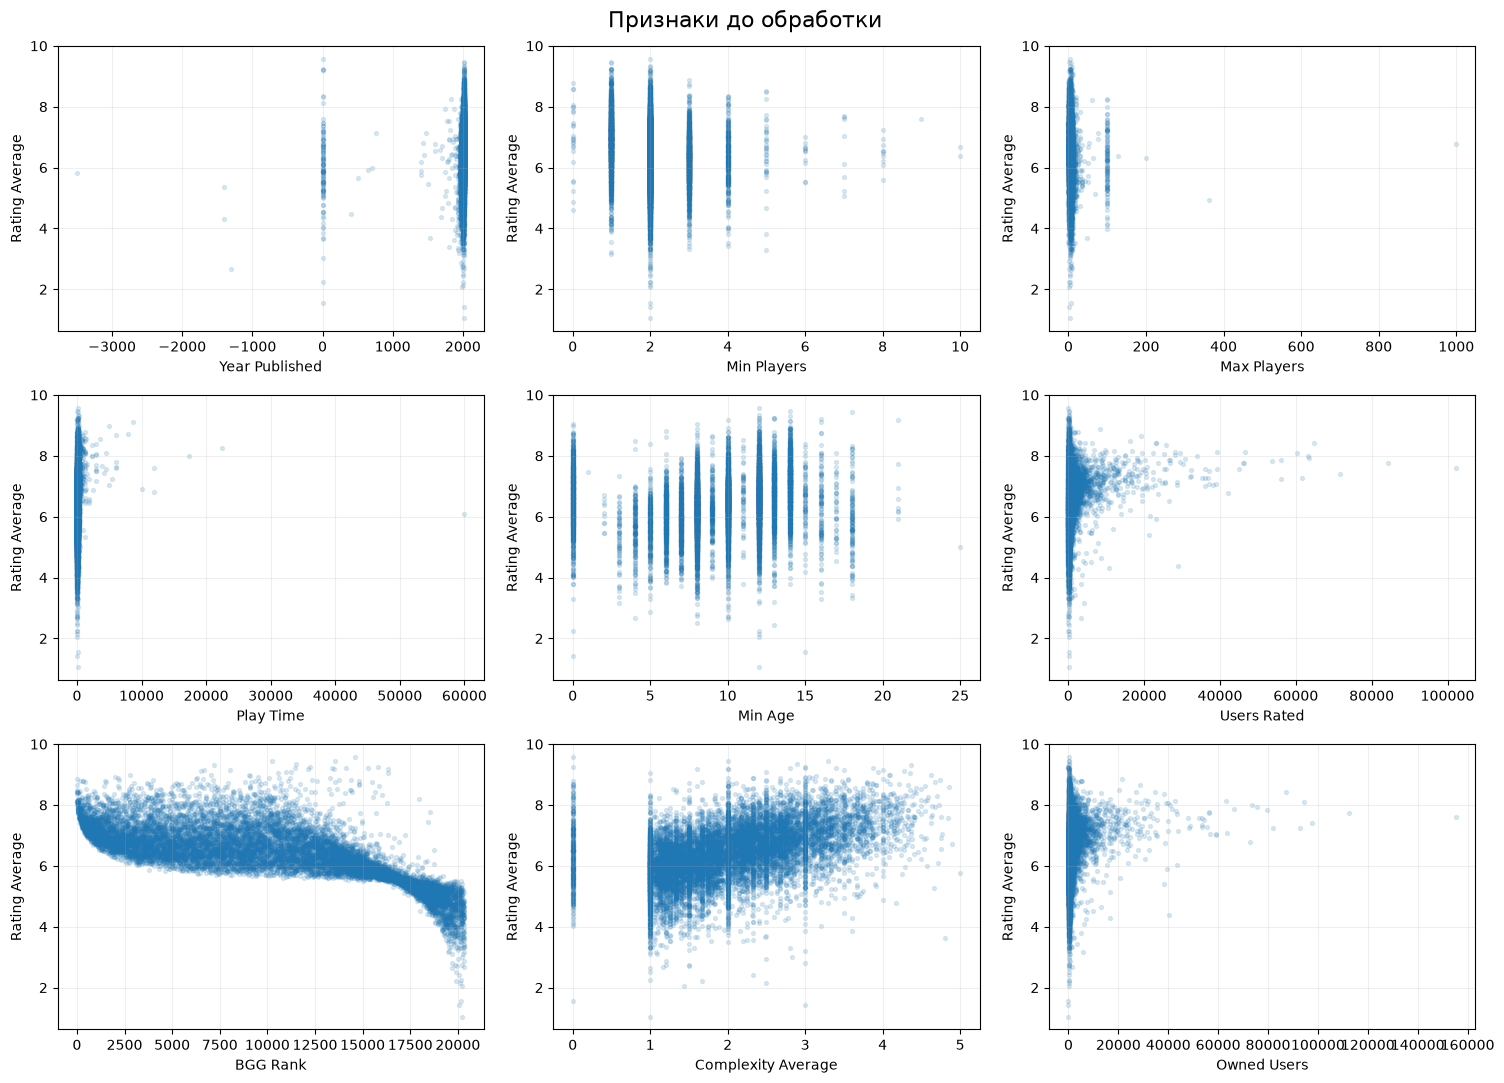

In [201]:
plt.figure(figsize=(15, 11))

for i, column in enumerate(features):
    plt.subplot(3, 3, i + 1)
    plt.scatter(x_train[column], y_train, alpha=0.15, s=8)
    plt.xlabel(column)
    plt.ylabel("Rating Average")
    plt.grid(alpha=0.2)

plt.suptitle("Признаки до обработки", fontsize=16)
plt.tight_layout()
plt.show()

## Уменьшение влияния выбросов

In [202]:
x_train_clean = x_train.copy()
x_valid_clean = x_valid.copy()

log_columns = ["Max Players", "Play Time", "Users Rated", "Owned Users", "BGG Rank"]

for column in log_columns:
    x_train_clean[column] = np.log1p(x_train_clean[column])
    x_valid_clean[column] = np.log1p(x_valid_clean[column])

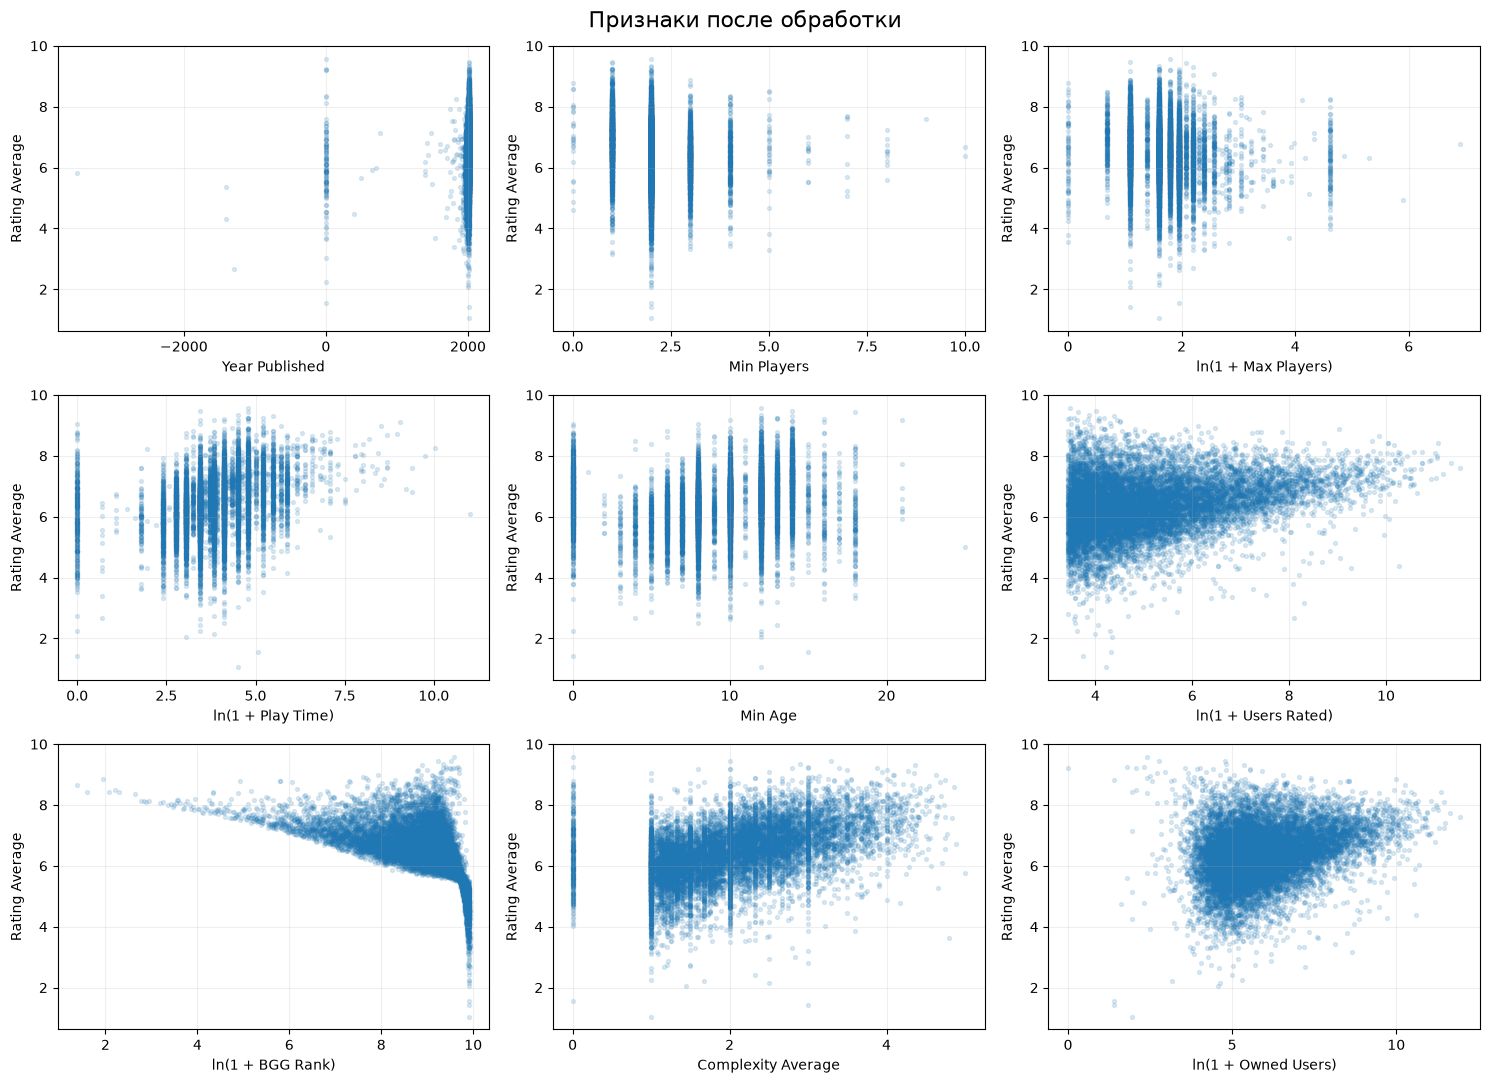

In [203]:
plt.figure(figsize=(15, 11))

for i, column in enumerate(features):
    plt.subplot(3, 3, i + 1)
    plt.scatter(x_train_clean[column], y_train, alpha=0.15, s=8)
    label = column
    if column in log_columns:
        label = "ln(1 + " + column + ")"
    plt.xlabel(label)
    plt.ylabel("Rating Average")
    plt.locator_params(axis="x", nbins=5)
    plt.grid(alpha=0.2)

plt.suptitle("Признаки после обработки", fontsize=16)
plt.tight_layout()
plt.show()

In [204]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train_clean)
x_valid_scaled = scaler.transform(x_valid_clean)

In [205]:
linear = LinearRegression()
linear.fit(x_train_scaled, y_train)

linear_train_predictions = linear.predict(x_train_scaled)
linear_predictions = linear.predict(x_valid_scaled)

results = []

results.append([
    "Линейная", mean_absolute_error(y_train, linear_train_predictions),
    mean_absolute_error(y_valid, linear_predictions),
    np.sqrt(mean_squared_error(y_valid, linear_predictions)),
    r2_score(y_valid, linear_predictions)
])

In [206]:
for degree in [2, 3, 4]:
    poly = PolynomialFeatures(degree=degree)
    x_train_poly = poly.fit_transform(x_train_scaled)
    x_valid_poly = poly.transform(x_valid_scaled)

    polynomial = LinearRegression()
    polynomial.fit(x_train_poly, y_train)

    poly_train_predictions = polynomial.predict(x_train_poly)
    poly_predictions = polynomial.predict(x_valid_poly)

    results.append([
        "Полином " + str(degree), mean_absolute_error(y_train, poly_train_predictions),
        mean_absolute_error(y_valid, poly_predictions),
        np.sqrt(mean_squared_error(y_valid, poly_predictions)),
        r2_score(y_valid, poly_predictions)
    ])

In [207]:
svm = SVR(kernel="rbf", C=10, epsilon=0.1)
svm.fit(x_train_scaled, y_train)

svm_train_predictions = svm.predict(x_train_scaled)
svm_predictions = svm.predict(x_valid_scaled)

results.append([
    "SVM (SVR)", mean_absolute_error(y_train, svm_train_predictions),
    mean_absolute_error(y_valid, svm_predictions),
    np.sqrt(mean_squared_error(y_valid, svm_predictions)),
    r2_score(y_valid, svm_predictions)
])

In [208]:
scores = pd.DataFrame(results, columns=[
    "Модель", "MAE обучение", "MAE проверка", "RMSE проверка", "R² проверка"
])
display(scores.round(4))

,Модель,MAE обучение,MAE проверка,RMSE проверка,R² проверка
0,Линейная,0.3997,0.4105,0.6305,0.5629
1,Полином 2,0.2855,0.2878,0.4576,0.7697
2,Полином 3,0.2148,0.2407,0.8824,0.1439
3,Полином 4,0.1836,0.6975,23.5571,-609.1928
4,SVM (SVR),0.1450,0.1751,0.3535,0.8626


## Прогноз для test

In [214]:
x_full = train[features].apply(pd.to_numeric, errors="coerce")
x_test = test[features].apply(pd.to_numeric, errors="coerce")

medians = x_full.median()
x_full = x_full.fillna(medians)
x_test = x_test.fillna(medians)

scaler = StandardScaler()
x_full_scaled = scaler.fit_transform(x_full)
x_test_scaled = scaler.transform(x_test)

svm = SVR(kernel="rbf", C=10, epsilon=0.1)
svm.fit(x_full_scaled, train["Rating Average"])

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",10
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


In [215]:
predictions = pd.read_csv("sample_submition.csv")
predictions = predictions.rename(columns={"index": "ID"})
predictions["Rating Average"] = svm.predict(x_test_scaled)

predictions.to_csv("predictions.csv", index=False)
display(predictions.head())

,ID,Rating Average
0,0,7.740047
1,1,7.921165
2,2,7.892404
3,3,7.841247
4,4,8.201806
